In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
url_UV = "/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt2/UV.csv"
df_UV = pd.read_csv(url_UV)

url_amarelo = "/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt2/amarelo.csv"
df_amarelo = pd.read_csv(url_amarelo)

url_azul = "/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt2/azul.csv"
df_azul = pd.read_csv(url_azul)

url_verde = "/content/drive/MyDrive/2025s2/F 740/Foto-eletrico/dados pt2/verde.csv"
df_verde = pd.read_csv(url_verde)

In [ ]:
df_azul

,V(mv),l(nA)
0,-3.000,-0.070
1,-2.600,-0.070
2,-2.300,-0.065
3,-2.000,-0.060
4,-1.800,-0.060
5,-1.700,-0.060
6,-1.600,-0.055
7,-1.500,-0.050
8,-1.400,-0.044
9,-1.131,0.000


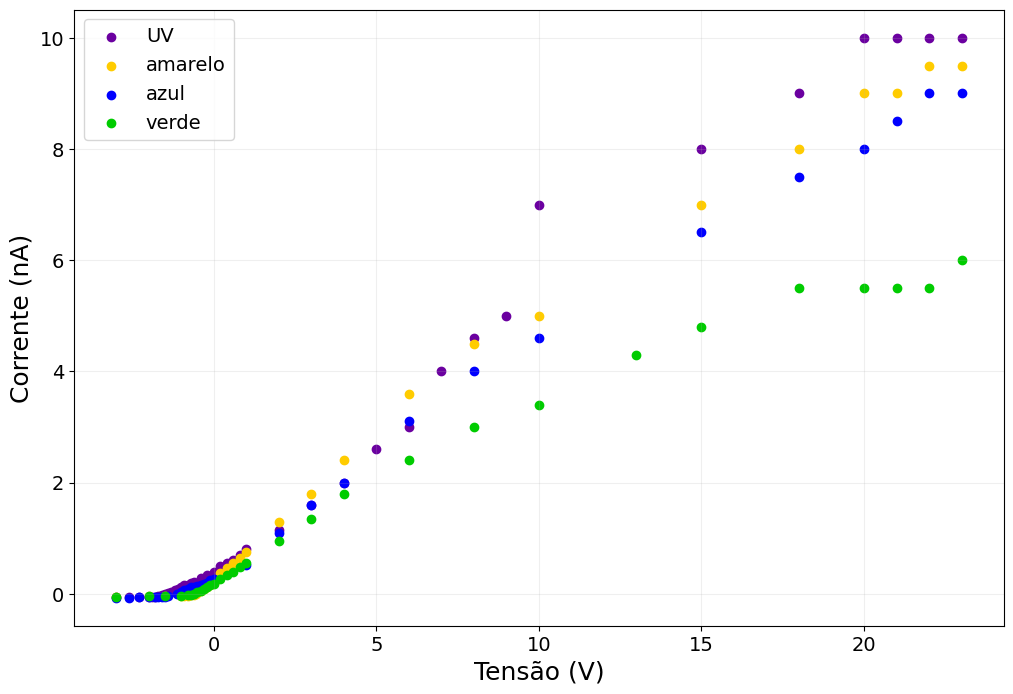

In [ ]:
plt.figure(figsize=(12,8))

plt.scatter(df_UV['V(mV)'], df_UV['I(nA)'],color="#6b00a0",label="UV")

plt.scatter(df_amarelo['V(mv)'], df_amarelo['I(nA)'],c="#ffcc00",label="amarelo")

plt.scatter(df_azul['V(mv)'], df_azul['l(nA)'],color="#0000ff",label="azul")

plt.scatter(df_verde['V(mv)'], df_verde['l(nA)'],color="#00cc00",label="verde")

plt.xlabel("Tensão (V)", fontsize=18)
plt.ylabel("Corrente (nA)", fontsize=18)
plt.grid(alpha=0.2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)


plt.show()


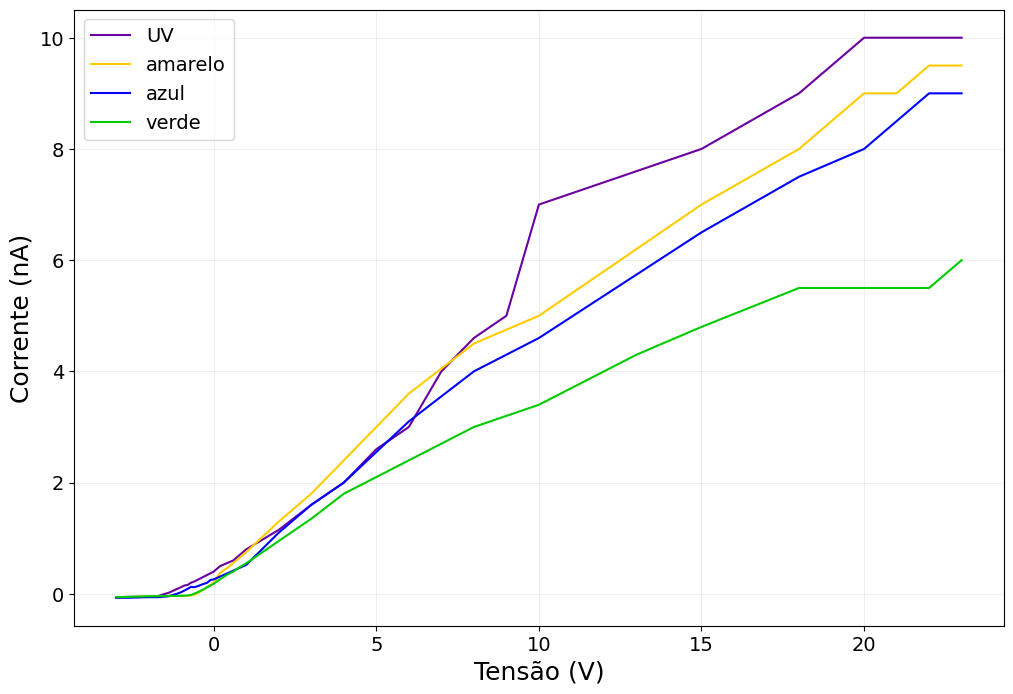

In [ ]:
plt.figure(figsize=(12,8))

plt.plot(df_UV['V(mV)'], df_UV['I(nA)'],color="#6b00a0",label="UV")

plt.plot(df_amarelo['V(mv)'], df_amarelo['I(nA)'],c="#ffcc00",label="amarelo")

plt.plot(df_azul['V(mv)'], df_azul['l(nA)'],color="#0000ff",label="azul")

plt.plot(df_verde['V(mv)'], df_verde['l(nA)'],color="#00cc00",label="verde")

plt.xlabel("Tensão (V)", fontsize=18)
plt.ylabel("Corrente (nA)", fontsize=18)
plt.grid(alpha=0.2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)


plt.show()


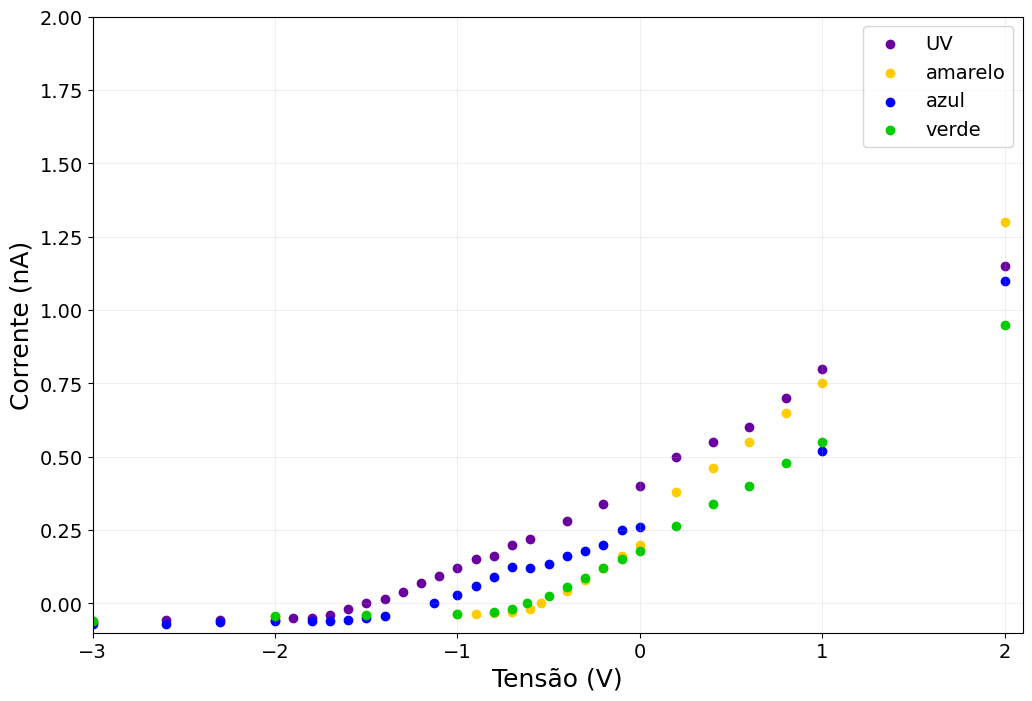

In [ ]:
plt.figure(figsize=(12,8))

plt.scatter(df_UV['V(mV)'], df_UV['I(nA)'],color="#6b00a0",label="UV")

plt.scatter(df_amarelo['V(mv)'], df_amarelo['I(nA)'],c="#ffcc00",label="amarelo")

plt.scatter(df_azul['V(mv)'], df_azul['l(nA)'],color="#0000ff",label="azul")

plt.scatter(df_verde['V(mv)'], df_verde['l(nA)'],color="#00cc00",label="verde")

plt.xlabel("Tensão (V)", fontsize=18)
plt.ylabel("Corrente (nA)", fontsize=18)
plt.grid(alpha=0.2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlim(-3,2.1)
plt.ylim(-0.1,2)
plt.show()


===== RESULTADOS =====
Inclinação a (h/e) = 3.2302e-15 ± 1.1933e-16 V·s
Intercepto b = -1.1338e+00 ± 7.8222e-02 V

--- Constante de Planck ---
h_exp = 5.1754e-34 ± 1.9119e-35 J·s
h_real = 6.6261e-34 J·s
Erro relativo de h = 21.89%

--- Razão h/e ---
(h/e)_exp = 3.2302e-15 ± 1.1933e-16 V·s
(h/e)_real = 4.1357e-15 V·s
Erro relativo de h/e = 21.89%


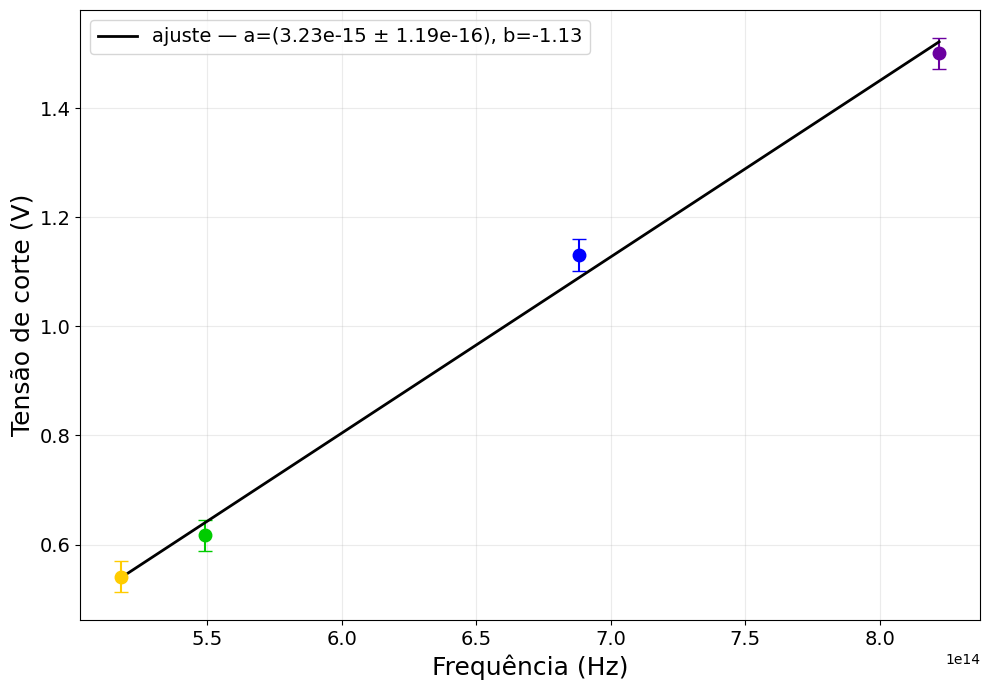

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Dados ---
Frequencias = np.array([8.20264e14, 6.87858e14, 5.48996e14, 5.18672e14])

V100 = np.array([
    1.5,
    1.131,
    0.617,
    0.541
])

# --- Cores reais do espectro ---
cores_plot = [
    "#6b00a0",  # UV
    "#0000ff",  # azul
    "#00cc00",  # verde
    "#ffcc00"   # amarelo
]

# --- Incerteza ---
sigmaV = 0.02886751346
errors = np.ones_like(V100) * sigmaV

# --- Modelo linear ---
def linha(f, a, b):
    return a*f + b

# Ajuste ponderado (SciPy)
params, cov = curve_fit(linha, Frequências, V100, sigma=errors, absolute_sigma=True)
a, b = params
da, db = np.sqrt(np.diag(cov))

# --- Constante de Planck experimental ---
e = 1.602176634e-19
h_exp = a * e
dh_exp = da * e

# --- h/e experimental ---
he_exp = a
dhe_exp = da

# --- Valores reais ---
h_real = 6.62607015e-34
he_real = 4.1356677e-15

# --- Erros relativos ---
erro_rel_h = abs((h_exp - h_real) / h_real) * 100
erro_rel_he = abs((he_exp - he_real) / he_real) * 100

print("===== RESULTADOS =====")
print(f"Inclinação a (h/e) = {a:.4e} ± {da:.4e} V·s")
print(f"Intercepto b = {b:.4e} ± {db:.4e} V")

print("\n--- Constante de Planck ---")
print(f"h_exp = {h_exp:.4e} ± {dh_exp:.4e} J·s")
print(f"h_real = {h_real:.4e} J·s")
print(f"Erro relativo de h = {erro_rel_h:.2f}%")

print("\n--- Razão h/e ---")
print(f"(h/e)_exp = {he_exp:.4e} ± {dhe_exp:.4e} V·s")
print(f"(h/e)_real = {he_real:.4e} V·s")
print(f"Erro relativo de h/e = {erro_rel_he:.2f}%")

# ---------------- Gráfico (padronização aplicada) ----------------
plt.figure(figsize=(10, 7))

alpha_val = 1.0   # mesma intensidade para todos

# Pontos coloridos com erro
for f, V, cor in zip(Frequências, V100, cores_plot):
    plt.errorbar(
        f, V, yerr=sigmaV, fmt='o',
        color=cor, markersize=9,
        capsize=5, alpha=alpha_val
    )

# Reta preta com mesmo alpha dos pontos
f_linha = np.linspace(Frequências.min(), Frequências.max(), 400)
plt.plot(
    f_linha, linha(f_linha, a, b),
    color="black", linewidth=2,
    alpha=alpha_val,
    label=f"ajuste — a=({a:.2e} ± {da:.2e}), b={b:.2f}"
)

plt.xlabel("Frequência (Hz)", fontsize=18)
plt.ylabel("Tensão de corte (V)", fontsize=18)
plt.grid(True, alpha=0.25)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()


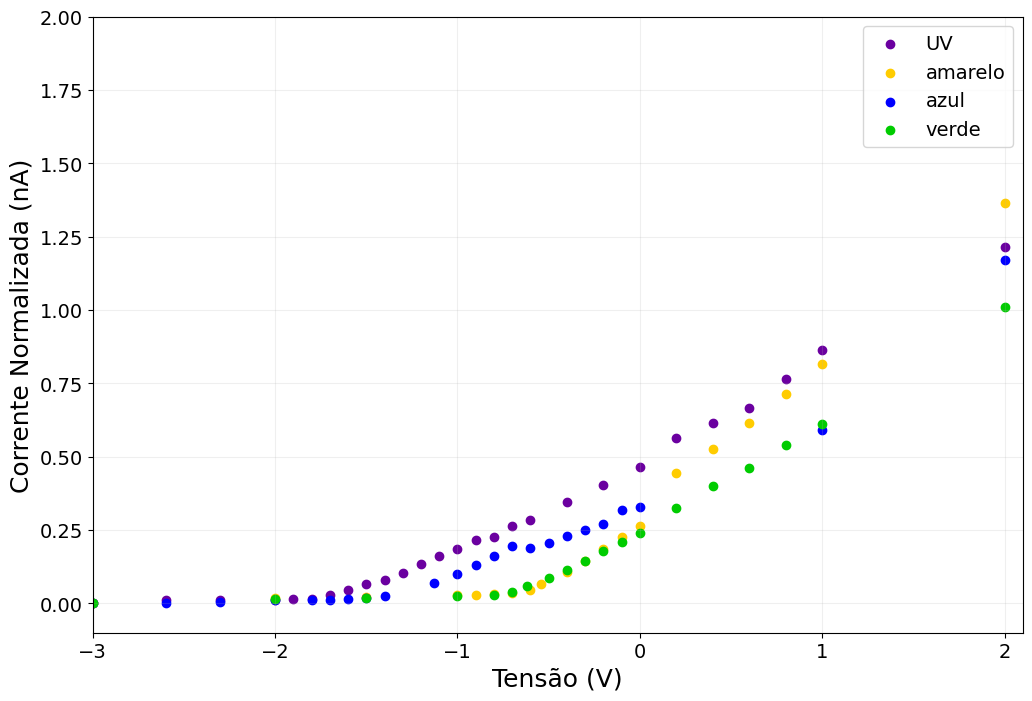

In [ ]:
# --- NORMALIZAÇÃO: deslocar corrente para que o mínimo vire 0 ---

df_UV['I_norm'] = df_UV['I(nA)'] - df_UV['I(nA)'].min()
df_amarelo['I_norm'] = df_amarelo['I(nA)'] - df_amarelo['I(nA)'].min()
df_azul['I_norm'] = df_azul['l(nA)'] - df_azul['l(nA)'].min()
df_verde['I_norm'] = df_verde['l(nA)'] - df_verde['l(nA)'].min()

# --- PLOT ---

plt.figure(figsize=(12,8))

plt.scatter(df_UV['V(mV)'], df_UV['I_norm'], color="#6b00a0", label="UV")
plt.scatter(df_amarelo['V(mv)'], df_amarelo['I_norm'], color="#ffcc00", label="amarelo")
plt.scatter(df_azul['V(mv)'], df_azul['I_norm'], color="#0000ff", label="azul")
plt.scatter(df_verde['V(mv)'], df_verde['I_norm'], color="#00cc00", label="verde")

plt.xlabel("Tensão (V)", fontsize=18)
plt.ylabel("Corrente Normalizada (nA)", fontsize=18)
plt.grid(alpha=0.2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.xlim(-3,2.1)
plt.ylim(-0.1,2)

plt.show()


(-0.2, 0.2)

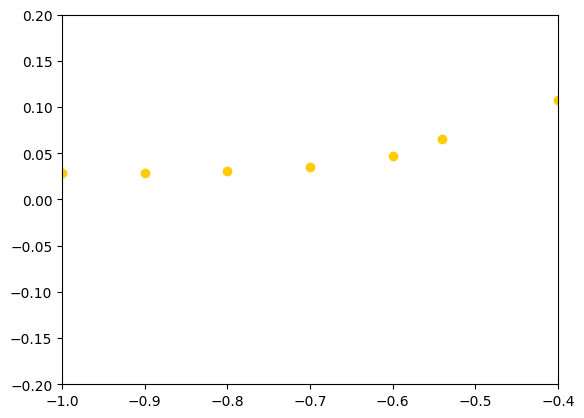

In [ ]:
plt.scatter(df_amarelo['V(mv)'], df_amarelo['I_norm'], color="#ffcc00", label="amarelo")
plt.xlim(-1,-0.4)
plt.ylim(-0.2,0.2)

===== RESULTADOS =====
Inclinação a (h/e) = 4.0759e-15 ± 1.1933e-16 V·s
Intercepto b = -1.5009e+00 ± 7.8222e-02 V

--- Constante de Planck ---
h_exp = 6.5303e-34 ± 1.9119e-35 J·s
h_real = 6.6261e-34 J·s
Erro relativo de h = 1.45%

--- Razão h/e ---
(h/e)_exp = 4.0759e-15 ± 1.1933e-16 V·s
(h/e)_real = 4.1357e-15 V·s
Erro relativo de h/e = 1.45%


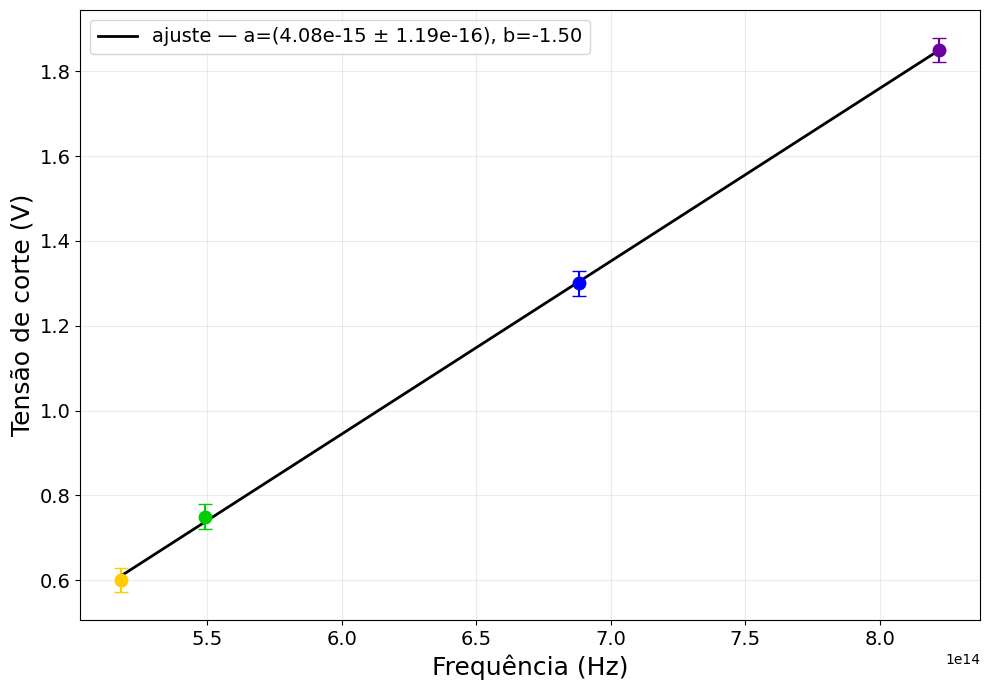

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Dados ---
Frequencias = np.array([8.20264e14, 6.87858e14, 5.48996e14, 5.18672e14])

V100 = np.array([
    1.85,
    1.3,
    0.75,
    0.6
])

# --- Cores reais do espectro ---
cores_plot = [
    "#6b00a0",  # UV
    "#0000ff",  # azul
    "#00cc00",  # verde
    "#ffcc00"   # amarelo
]

# --- Incerteza ---
sigmaV = 0.02886751346
errors = np.ones_like(V100) * sigmaV

# --- Modelo linear ---
def linha(f, a, b):
    return a*f + b

# Ajuste ponderado (SciPy)
params, cov = curve_fit(linha, Frequências, V100, sigma=errors, absolute_sigma=True)
a, b = params
da, db = np.sqrt(np.diag(cov))

# --- Constante de Planck experimental ---
e = 1.602176634e-19
h_exp = a * e
dh_exp = da * e

# --- h/e experimental ---
he_exp = a
dhe_exp = da

# --- Valores reais ---
h_real = 6.62607015e-34
he_real = 4.1356677e-15

# --- Erros relativos ---
erro_rel_h = abs((h_exp - h_real) / h_real) * 100
erro_rel_he = abs((he_exp - he_real) / he_real) * 100

print("===== RESULTADOS =====")
print(f"Inclinação a (h/e) = {a:.4e} ± {da:.4e} V·s")
print(f"Intercepto b = {b:.4e} ± {db:.4e} V")

print("\n--- Constante de Planck ---")
print(f"h_exp = {h_exp:.4e} ± {dh_exp:.4e} J·s")
print(f"h_real = {h_real:.4e} J·s")
print(f"Erro relativo de h = {erro_rel_h:.2f}%")

print("\n--- Razão h/e ---")
print(f"(h/e)_exp = {he_exp:.4e} ± {dhe_exp:.4e} V·s")
print(f"(h/e)_real = {he_real:.4e} V·s")
print(f"Erro relativo de h/e = {erro_rel_he:.2f}%")

# ---------------- Gráfico (padronização aplicada) ----------------
plt.figure(figsize=(10, 7))

alpha_val = 1.0   # mesma intensidade para todos

# Pontos coloridos com erro
for f, V, cor in zip(Frequências, V100, cores_plot):
    plt.errorbar(
        f, V, yerr=sigmaV, fmt='o',
        color=cor, markersize=9,
        capsize=5, alpha=alpha_val
    )

# Reta preta com mesmo alpha dos pontos
f_linha = np.linspace(Frequências.min(), Frequências.max(), 400)
plt.plot(
    f_linha, linha(f_linha, a, b),
    color="black", linewidth=2,
    alpha=alpha_val,
    label=f"ajuste — a=({a:.2e} ± {da:.2e}), b={b:.2f}"
)

plt.xlabel("Frequência (Hz)", fontsize=18)
plt.ylabel("Tensão de corte (V)", fontsize=18)
plt.grid(True, alpha=0.25)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.tight_layout()
plt.show()
